# Notebook 1 — Análisis exploratorio (EDA) y limpieza del dataset Online Retail II

**TFM:** Análisis comparativo de plataformas de Business Intelligence para la visualización y soporte a la toma de decisiones empresariales: Power BI, Tableau y Looker Studio
**Autor:** Diego Encalada García — Máster Universitario en Análisis y Visualización de Datos Masivos (UNIR)

**Declaración de uso de IA:** este notebook fue generado con asistencia de Claude (Anthropic, modelo de lenguaje de gran escala), con autorización de la directora del TFM. Las decisiones de limpieza (tratamiento de cancelaciones, nulos, precios no válidos y alcance geográfico) fueron tomadas por el autor. El autor revisó y ejecutó el código y es responsable de su contenido.

**Fuente de datos:** Chen, D. (2012). *Online Retail II* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D

**Salidas del notebook:**
- `online_retail_limpio.csv` — dataset limpio; es el mismo archivo que se carga en Power BI, Tableau y Looker Studio (pesa menos de 100 MB para cumplir el límite de carga de CSV de Looker Studio)
- `bitacora_limpieza.csv` — registro de cada paso de limpieza (filas antes, eliminadas, motivo)
- `registros_excluidos.csv` — todas las filas excluidas, con el motivo
- `figuras/` — figuras en PNG (300 ppp) para la memoria

## 1. Configuración y librerías

In [1]:
import logging
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Ruta del archivo original descargado del UCI Machine Learning Repository
RUTA_EXCEL = "online_retail_II.xlsx"
HOJAS = ["Year 2009-2010", "Year 2010-2011"]

# Archivos de salida
RUTA_SALIDA = "online_retail_limpio.csv"
RUTA_BITACORA = "bitacora_limpieza.csv"
RUTA_EXCLUIDOS = "registros_excluidos.csv"
CARPETA_FIGURAS = Path("figuras")
CARPETA_FIGURAS.mkdir(exist_ok=True)

# Límite de Looker Studio para subir un CSV (documentación oficial de Google)
LIMITE_LOOKER_MB = 100

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 20)

# Estilo sobrio para las figuras de la memoria (Calibri, como el texto de la plantilla)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
COLOR = "#2F6DB5"

# Formato numérico en español para las figuras: 34.335 y 2,5
def miles(valor, _=None):
    return f"{valor:,.0f}".replace(",", ".")

def decimal(valor, _=None):
    return f"{valor:.1f}".replace(".", ",")
plt.rcParams.update({
    "font.family": ["Calibri", "DejaVu Sans"],
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#999999",
    "axes.grid": True,
    "grid.color": "#E5E5E5",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

## 2. Carga de datos

El archivo original trae las transacciones divididas en dos hojas (una por periodo). Se leen ambas y se unen en un solo DataFrame. `StockCode` e `Invoice` se leen como texto porque contienen letras (por ejemplo, las facturas canceladas empiezan con "C").

In [2]:
hojas = pd.read_excel(
    RUTA_EXCEL,
    sheet_name=HOJAS,
    dtype={"Invoice": str, "StockCode": str},
)

df = pd.concat(hojas.values(), ignore_index=True)

for nombre, hoja in hojas.items():
    print(f"{nombre}: {len(hoja):,} filas")
print(f"Total unido: {len(df):,} filas x {df.shape[1]} columnas")

Year 2009-2010: 525,461 filas
Year 2010-2011: 541,910 filas
Total unido: 1,067,371 filas x 8 columnas


## 3. Perfil inicial (EDA)

In [3]:
print("Tipos de dato:")
print(df.dtypes)

print("\nValores nulos por columna:")
nulos = pd.DataFrame({
    "nulos": df.isnull().sum(),
    "porcentaje": (df.isnull().mean() * 100).round(2),
})
print(nulos)

print(f"\nFilas duplicadas exactas: {df.duplicated().sum():,}")
print(f"Rango de fechas: {df['InvoiceDate'].min()} a {df['InvoiceDate'].max()}")
print(f"Facturas únicas: {df['Invoice'].nunique():,}")
print(f"Productos únicos (StockCode): {df['StockCode'].nunique():,}")
print(f"Clientes únicos (Customer ID): {df['Customer ID'].nunique():,}")
print(f"Países: {df['Country'].nunique()}")

Tipos de dato:
Invoice                   str
StockCode                 str
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

Valores nulos por columna:
              nulos  porcentaje
Invoice           0        0.00
StockCode         0        0.00
Description    4382        0.41
Quantity          0        0.00
InvoiceDate       0        0.00
Price             0        0.00
Customer ID  243007       22.77
Country           0        0.00

Filas duplicadas exactas: 34,335
Rango de fechas: 2009-12-01 07:45:00 a 2011-12-09 12:50:00
Facturas únicas: 53,628
Productos únicos (StockCode): 5,305
Clientes únicos (Customer ID): 5,942
Países: 43


## 4. Distribución de las variables numéricas

Se revisan `Quantity` y `Price` para detectar valores negativos, ceros y valores extremos. Los histogramas se recortan entre los percentiles 1 y 99 para que los extremos no oculten la forma de la distribución. La figura se guarda para la memoria (apartado 5.2).

          Quantity        Price
count 1,067,371.00 1,067,371.00
mean          9.94         4.65
std         172.71       123.55
min     -80,995.00   -53,594.36
1%           -3.00         0.21
25%           1.00         1.25
50%           3.00         2.10
75%          10.00         4.15
99%         100.00        18.00
max      80,995.00    38,970.00


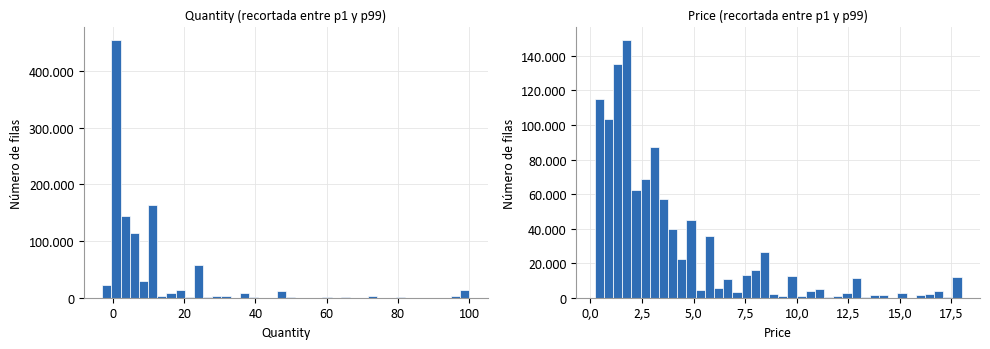

In [4]:
print(df[["Quantity", "Price"]].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]))

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.6))
for eje, col in zip(ejes, ["Quantity", "Price"]):
    p1, p99 = df[col].quantile([0.01, 0.99])
    eje.hist(df[col].clip(p1, p99), bins=40, color=COLOR, edgecolor="white", linewidth=0.5)
    eje.set_title(f"{col} (recortada entre p1 y p99)", fontsize=10)
    eje.set_xlabel(col)
    eje.set_ylabel("Número de filas")
    eje.yaxis.set_major_formatter(miles)
    eje.xaxis.set_major_formatter(decimal if col == "Price" else miles)
fig.tight_layout()
fig.savefig(CARPETA_FIGURAS / "fig_distribucion_quantity_price.png")
plt.show()

## 5. Conteo de problemas de calidad detectados

In [5]:
es_cancelacion = df["Invoice"].str.startswith("C", na=False)

problemas = pd.DataFrame({
    "problema": [
        "Facturas canceladas (Invoice empieza con 'C')",
        "Quantity <= 0",
        "Price <= 0",
        "Customer ID nulo",
        "Filas duplicadas exactas",
    ],
    "filas": [
        es_cancelacion.sum(),
        (df["Quantity"] <= 0).sum(),
        (df["Price"] <= 0).sum(),
        df["Customer ID"].isnull().sum(),
        df.duplicated().sum(),
    ],
})
problemas["porcentaje"] = (problemas["filas"] / len(df) * 100).round(2)
print(problemas.to_string(index=False))

print("\nFilas por país (top 10):")
print(df["Country"].value_counts().head(10))
print(f"\nPeso de United Kingdom: {(df['Country'] == 'United Kingdom').mean() * 100:.2f}%")

                                     problema  filas  porcentaje
Facturas canceladas (Invoice empieza con 'C')  19494        1.83
                                Quantity <= 0  22950        2.15
                                   Price <= 0   6207        0.58
                             Customer ID nulo 243007       22.77
                     Filas duplicadas exactas  34335        3.22

Filas por país (top 10):
Country
United Kingdom    981330
EIRE               17866
Germany            17624
France             14330
Netherlands         5140
Spain               3811
Switzerland         3189
Belgium             3123
Portugal            2620
Australia           1913
Name: count, dtype: int64

Peso de United Kingdom: 91.94%


## 6. Limpieza con bitácora

Decisiones del autor:

| Problema | Decisión | Justificación |
|---|---|---|
| Duplicados exactos | Se eliminan | Son registros repetidos que inflarían ventas y cantidades |
| Cancelaciones (factura con "C") | Se excluyen y se documentan | El análisis se centra en ventas efectivas |
| Quantity <= 0 sin ser cancelación | Se excluyen y se documentan | Son ajustes de inventario, no ventas |
| Price <= 0 | Se eliminan y se documentan | Ajustes contables o muestras sin valor; distorsionan totales y promedios |
| Ventas anuladas por completo después | Se eliminan y se documentan | Las facturas 541431 y 581483 se anularon minutos después (C541433 y C581484). Al quitar solo la línea "C", la venta original quedaría e inflaría las ventas en unos 245.000 |
| Códigos que no son productos | Se excluyen y se documentan | Portes (POST, DOT, C2), ajustes manuales (M, ADJUST, B), comisiones (AMAZONFEE, BANK CHARGES), descuentos, muestras, pruebas y vales regalo. El análisis se centra en la venta de productos |
| Customer ID nulo | Se mantienen | Son ventas reales; se excluyen solo en análisis por cliente (Customer ID vacío) |
| Países | Se mantienen todos | Más volumen para medir rendimiento y permite visualizaciones geográficas |

Cada paso registra en la bitácora cuántas filas había antes, cuántas se eliminaron y el motivo. Las filas excluidas se guardan con su motivo.

In [6]:
bitacora = []
excluidos = []

def registrar(paso, filas_antes, filas_despues, motivo):
    bitacora.append({
        "paso": paso,
        "filas_antes": filas_antes,
        "filas_eliminadas": filas_antes - filas_despues,
        "filas_despues": filas_despues,
        "motivo": motivo,
    })

def excluir(df, mascara, paso, motivo):
    """Quita las filas que cumplen la máscara, las guarda con su motivo y registra el paso."""
    filas_antes = len(df)
    quitadas = df[mascara].copy()
    quitadas["motivo_exclusion"] = motivo
    excluidos.append(quitadas)
    df = df[~mascara].copy()
    registrar(paso, filas_antes, len(df), motivo)
    return df

limpio = df.copy()
registrar("0. Dataset original (2 hojas unidas)", len(limpio), len(limpio), "Punto de partida")

# Paso 1: duplicados exactos (se conserva la primera aparición)
limpio = excluir(limpio, limpio.duplicated(keep="first"),
                 "1. Duplicados exactos", "Fila idéntica a otra ya existente")

# Paso 2: cancelaciones
limpio = excluir(limpio, limpio["Invoice"].str.startswith("C", na=False),
                 "2. Cancelaciones", "Factura cancelada (Invoice empieza con 'C')")

# Paso 3: cantidades no positivas que no son cancelaciones
limpio = excluir(limpio, limpio["Quantity"] <= 0,
                 "3. Quantity <= 0 (no cancelación)", "Ajuste de inventario, no es una venta")

# Paso 4: precios no positivos
limpio = excluir(limpio, limpio["Price"] <= 0,
                 "4. Price <= 0", "Precio cero o negativo: ajuste contable o muestra sin valor")

# Paso 5: ventas anuladas por completo minutos después (verificado en el dataset original)
VENTAS_ANULADAS = {"541431": "C541433", "581483": "C581484"}
for original, cancelacion in VENTAS_ANULADAS.items():
    assert cancelacion in set(df["Invoice"]), f"No se encontró la cancelación {cancelacion}"
limpio = excluir(limpio, limpio["Invoice"].isin(VENTAS_ANULADAS.keys()),
                 "5. Ventas anuladas posteriormente",
                 "Venta anulada por completo después (541431 por C541433; 581483 por C581484)")

# Paso 6: códigos que no corresponden a productos
CODIGOS_NO_PRODUCTO = {
    "POST", "DOT", "C2",                 # portes y envíos
    "M", "m", "ADJUST", "ADJUST2", "B",  # ajustes manuales y contables
    "AMAZONFEE", "BANK CHARGES",         # comisiones
    "D", "S", "PADS",                    # descuentos, muestras y relleno
    "TEST001", "TEST002",                # productos de prueba
}
es_no_producto = (
    limpio["StockCode"].isin(CODIGOS_NO_PRODUCTO)
    | limpio["StockCode"].str.startswith("gift_", na=False)   # vales regalo
)
print("Códigos excluidos por no ser productos:")
print(limpio[es_no_producto].groupby("StockCode")["Description"].first().to_string())
limpio = excluir(limpio, es_no_producto,
                 "6. Códigos que no son productos",
                 "Portes, ajustes, comisiones, descuentos, muestras, pruebas y vales regalo")

sin_cliente = limpio["Customer ID"].isnull().sum()
registrar("7. Customer ID nulo", len(limpio), len(limpio),
          f"Se mantienen {sin_cliente:,} filas (ventas reales sin cliente identificado)")

bitacora_df = pd.DataFrame(bitacora)
print()
print(bitacora_df.to_string(index=False))

Códigos excluidos por no ser productos:
StockCode
ADJUST          Adjustment by john on 26/01/2010 16
ADJUST2         Adjustment by Peter on Jun 25 2010 
AMAZONFEE                                AMAZON FEE
B                                   Adjust bad debt
BANK CHARGES                           Bank Charges
C2                                         CARRIAGE
D                                          Discount
DOT                                  DOTCOM POSTAGE
M                                            Manual
PADS                     PADS TO MATCH ALL CUSHIONS
POST                                        POSTAGE
S                                           SAMPLES
TEST001                     This is a test product.
TEST002                     This is a test product.
gift_0001_10     Dotcomgiftshop Gift Voucher £10.00
gift_0001_20     Dotcomgiftshop Gift Voucher £20.00
gift_0001_30     Dotcomgiftshop Gift Voucher £30.00
gift_0001_40     Dotcomgiftshop Gift Voucher £40.00
gift_0001_50  

### Figura: filas eliminadas por paso de limpieza

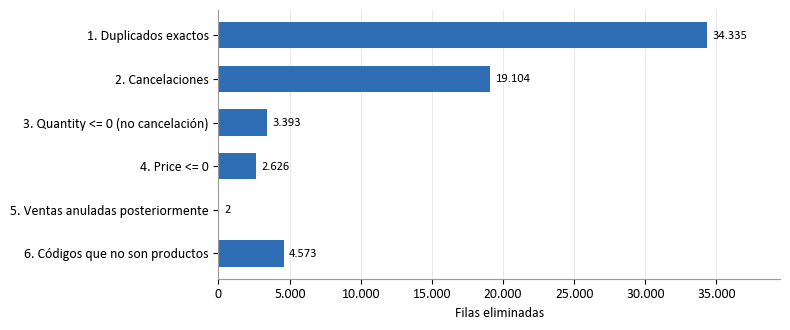

In [7]:
pasos = bitacora_df[bitacora_df["filas_eliminadas"] > 0].iloc[::-1]

fig, eje = plt.subplots(figsize=(8, 3.4))
barras = eje.barh(pasos["paso"], pasos["filas_eliminadas"], color=COLOR, height=0.6)
eje.bar_label(barras, labels=[miles(v) for v in pasos["filas_eliminadas"]], padding=4, fontsize=9)
eje.set_xlabel("Filas eliminadas")
eje.xaxis.set_major_formatter(miles)
eje.grid(axis="y", visible=False)
eje.set_xlim(0, pasos["filas_eliminadas"].max() * 1.15)
fig.tight_layout()
fig.savefig(CARPETA_FIGURAS / "fig_filas_eliminadas_por_paso.png")
plt.show()

## 7. Tipos finales y archivo para las plataformas

- `Customer ID` se convierte a texto sin decimales (pandas lo lee como 13085.0 por culpa de los nulos). Así las herramientas de BI lo tratan como identificador y no como una medida que se suma. Las ventas sin cliente quedan con el campo vacío.
- `Description` se limpia de espacios sobrantes.

El CSV final lleva **solo las 8 columnas originales**. El importe de cada línea (Quantity × Price), el año y el mes se crean como campos calculados **dentro de cada plataforma**. Así el archivo baja de 100 MB (límite de Looker Studio), las tres herramientas reciben exactamente el mismo archivo, y crear esos campos forma parte de lo que se compara en usabilidad.

In [8]:
cliente = limpio["Customer ID"].astype("Int64")   # 13085.0 -> 13085, conserva los nulos
limpio["Customer ID"] = cliente.astype("string").fillna("")
limpio["Description"] = limpio["Description"].str.strip()

COLUMNAS = ["Invoice", "StockCode", "Description", "Quantity",
            "InvoiceDate", "Price", "Customer ID", "Country"]
limpio = limpio[COLUMNAS]
limpio.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom


## 8. Validaciones del dataset limpio

In [9]:
assert not limpio["Invoice"].str.startswith("C", na=False).any(), "Quedan cancelaciones"
assert (limpio["Quantity"] > 0).all(), "Quedan cantidades no positivas"
assert (limpio["Price"] > 0).all(), "Quedan precios no positivos"
assert not limpio["Invoice"].isin(VENTAS_ANULADAS.keys()).any(), "Quedan ventas anuladas"
assert not limpio["StockCode"].isin(CODIGOS_NO_PRODUCTO).any(), "Quedan códigos no producto"

total_excluidas = sum(len(e) for e in excluidos)
assert len(df) == len(limpio) + total_excluidas, "Las filas no cuadran"

ventas = (limpio["Quantity"] * limpio["Price"]).sum()

print("Validaciones superadas")
print(f"Filas originales: {len(df):,}")
print(f"Filas excluidas:  {total_excluidas:,} ({total_excluidas / len(df) * 100:.2f}%)")
print(f"Filas limpias:    {len(limpio):,} ({len(limpio) / len(df) * 100:.2f}%)")
print(f"Filas sin Customer ID (se mantienen): {(limpio['Customer ID'] == '').sum():,}")
print(f"Ventas totales (Quantity x Price): {ventas:,.2f}")
print(f"Facturas: {limpio['Invoice'].nunique():,} | Productos: {limpio['StockCode'].nunique():,} | Países: {limpio['Country'].nunique()}")
print(f"Rango de fechas: {limpio['InvoiceDate'].min()} a {limpio['InvoiceDate'].max()}")
print(f"Quantity máxima: {limpio['Quantity'].max():,} | Price máximo: {limpio['Price'].max():,.2f}")

Validaciones superadas
Filas originales: 1,067,371
Filas excluidas:  64,033 (6.00%)
Filas limpias:    1,003,338 (94.00%)
Filas sin Customer ID (se mantienen): 226,761
Ventas totales (Quantity x Price): 19,398,208.42
Facturas: 39,514 | Productos: 4,894 | Países: 43
Rango de fechas: 2009-12-01 07:45:00 a 2011-12-09 12:50:00
Quantity máxima: 19,152 | Price máximo: 1,157.15


## 9. Exportación

Estas cifras de control (filas, ventas totales, facturas) sirven para comprobar que cada plataforma cargó los datos completos: los mismos totales deben aparecer en Power BI, Tableau y Looker Studio.

In [10]:
limpio.to_csv(RUTA_SALIDA, index=False, encoding="utf-8")
bitacora_df.to_csv(RUTA_BITACORA, index=False, encoding="utf-8")
pd.concat(excluidos, ignore_index=True).to_csv(RUTA_EXCLUIDOS, index=False, encoding="utf-8")

tamano_mb = Path(RUTA_SALIDA).stat().st_size / 1024 ** 2
print(f"Guardado: {RUTA_SALIDA} ({len(limpio):,} filas, {tamano_mb:.1f} MB)")
print(f"Guardado: {RUTA_BITACORA}")
print(f"Guardado: {RUTA_EXCLUIDOS} ({total_excluidas:,} filas)")
print(f"Figuras en: {CARPETA_FIGURAS.resolve()}")
assert tamano_mb < LIMITE_LOOKER_MB, f"El CSV supera {LIMITE_LOOKER_MB} MB: Looker Studio no lo aceptará"
print(f"El CSV cumple el límite de {LIMITE_LOOKER_MB} MB de Looker Studio")

Guardado: online_retail_limpio.csv (1,003,338 filas, 84.5 MB)
Guardado: bitacora_limpieza.csv
Guardado: registros_excluidos.csv (64,033 filas)
Figuras en: C:\Users\diego\OneDrive\Desktop\TFM UNIR\analisis_data_tfm_py\figuras
El CSV cumple el límite de 100 MB de Looker Studio
